# Metacognitive efficiency with $Meta-I$

> **Level** Intermediate · **Time** 20 minutes · **Prerequisites** basic signal detection theory ·
> **cpm components** [`EstimatorMetaI`](cpm.applications.metainformation_theoretic.EstimatorMetaI) ·
> **Data** [`load_metacognition_data`](#cpm.datasets.load_metacognition_data)
 
Meta-I quantifies how well confidence ratings give insight about correct vs. incorrect decisions from the mutual information between accuracy and confidence. If someone's metacognitive abilities are good, they are more confident when they are right, than when they are wrong.
In this example, we estimate meta-I with [`EstimatorMetaI`](#cpm.applications.metainformation_theoretic.EstimatorMetaI) for participants of a perceptual decision-making task.


**What you'll learn**

- what meta-$I$, $Meta-Ir1$ and $Meta-Ir2$ measure,
- how meta-$I$ differs from meta-$d'$
- how to prepare trial-level decision and confidence data,
- how to estimate meta-$I$ for each participant, and interpret the estimates.
<br>

The measures implemented are based on:
> Dayan, P. (2023). Metacognitive Information Theory.  
> Open Mind: Discoveries in Cognitive Science.  
> https://doi.org/10.1162/opmi_a_00091


In [2]:
import cpm
import numpy as np
import pandas as pd
import scipy.stats
import warnings
import matplotlib.pyplot as plt

from cpm.applications.signal_detection import EstimatorMetaD
from cpm.applications.metainformation_theoretic import EstimatorMetaI

## Background
Meta-I is a measure of metacognitive sensitivity as proposed by Dayan (2023). It essentially quantifies how much our own confidence in a choice can tell us about being right.
Meta-I looks at how much the confidence ratings reduces of the **uncertainty about accuracy** using mutual information:
$$\text{meta-I} = H_2(r) - H_2(r \mid c)$$

in which $H_2(r)$ is the entropy of the accuracy, and $H_2(r\mid c)$ is the remaining entropy about accuracy after seeing the confidence rating $c$. Meta-I is 0, when the confidence tells us nothing about accuracy and approaches $H_2(r)$, the more confidence predicts accuracy.

Metacognitive sensitivity is tied to the ability to reflect accuracy in the confidence rating about that choice, so ideally confidence should be higher for correct and lower for incorrect choices.


Dayan additionally proposed two types of metacognitive efficiency:

 - **Meta-Ir1** = $meta-I / meta-I(d′)$: mutual information is normalized by the mutual information a naive Baysian observer would produce idealy given a certain d' (type 1 SDT perceptual sensitivity).

 - **Meta-Ir2** = $meta-I / H₂(r)$: mutual information is normalized by $H_2(r)$ the total uncertainty there is about accuracy in the first place (theoretical upper bound of meta-I). 

## Exploring the data
The data was collected using the BrainExplorer app's (Marzuki et al., 2025) Space Observer task, where participants have to decide which type of alien (e.g. green vs orange) is more numerous and then rated their confidence in that choice from 0 ("totally guessing") to 100 ("totally certain") resulting in a continous confidence rating.

In [3]:
from cpm.datasets import load_metacognition_data

df = load_metacognition_data()
df.head()

,participant,signal,stimulus_intensity,response,confidence,accuracy
0,1,1,8,0,56,0
1,1,0,12,0,65,1
2,1,0,12,1,22,0
3,1,1,16,1,62,1
4,1,0,16,0,60,1


The columns:
- `signal`: type of alien more numerous (S1=0, S2=1) with amount of stimulus_intensity
- `stimulus_intensity`: the absolute difference betweent the number of aliens (ranges between 2-34)`
- `response`: decision/choice of the participant (S1=0, S2=1)
- `confidence`: continous confidence rating (in this case 0-100)
- `accuracy`: whether participants choice (response) was correct (consistent with the stimulus).

## Estimating meta-I

To determine the mutual information, the continous confidence rating is divided into arbitary number of quantile (equally?) sized bins. For each bin the number of correct and incorrect trials are counted and the entropy of the accuracy given that the confidence is e.g. low vs. high (in case of 2 bins) or in this example 1/2/3 or 4 bins, is determined.

In constrast to meta-d', Meta-I is highly dependent on the number of bins used. Increasing the number of bins increases the "resolution" of Meta-I, if participants "made use" of the different confidence levels. If binning is too granular, could lead to empty bins (bins with no trials) or binning process not possible, as bins contain too many similar confidence values. The optimal number of bins is something to play around with and must be explored given the data.

In [4]:
from cpm.applications.metainformation_theoretic import EstimatorMetaI

estimator_metaI = EstimatorMetaI(
    data=df, 
    bins=4, 
    matched_bins=True, 
    ppt_identifier="participant",
    dprime_correction = 1
)

estimator_metaI.estimate()
results_metaI = estimator_metaI.export()

In [177]:
display(results_metaI[["ppt", "d_prime", "meta_I", "meta_Ir1", "meta_Ir2"]].head().round(2))

,ppt,d_prime,meta_I,meta_Ir1,meta_Ir2
0,1,1.36,0.09,1.19,0.11
1,2,1.03,0.05,1.03,0.06
2,3,1.04,0.02,0.41,0.02
3,4,1.27,0.02,0.31,0.03
4,5,1.26,0.09,1.38,0.11


For each participant d', meta-I and the two efficiency measures are displayed. Export also holds the number of correct and incorrect trials in total and per confidence bin, from which the mutual information is inferred. As well as the individual thresholds for creating the quanitle bins.

## Results

First we will look at the distributions and the ranges of `meta-I`, `meta-Ir1` and `meta-Ir2`.

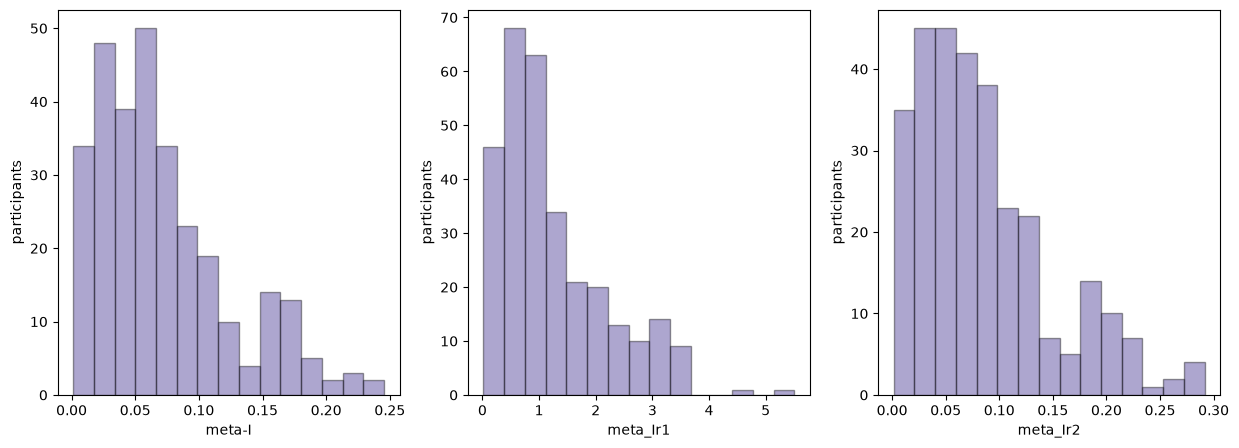

In [118]:
meta_I = results_metaI["meta_I"]
meta_Ir1 = results_metaI["meta_Ir1"]
meta_Ir2 = results_metaI["meta_Ir2"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].hist(results_metaI["meta_I"], bins=15, alpha=0.4, color="#328", edgecolor="black")
axes[0].set_xlabel("meta-I")
axes[0].set_ylabel("participants")

axes[1].hist(results_metaI["meta_Ir1"], bins=15, alpha=0.4, color="#328", edgecolor="black")
axes[1].set_xlabel("meta_Ir1")
axes[1].set_ylabel("participants")

axes[2].hist(results_metaI["meta_Ir2"],bins=15, alpha=0.4, color="#328", edgecolor="black")
axes[2].set_xlabel("meta_Ir2")
axes[2].set_ylabel("participants")
plt.show()

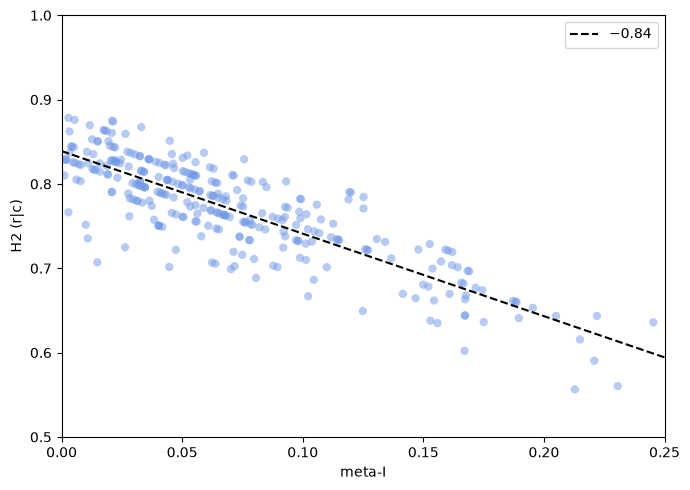

In [176]:
fig, axes = plt.subplots(figsize = (7, 5))
axes.scatter(results_metaI["meta_I"], results_metaI["H2r_given_c"], alpha=0.5, color="#7198E6", edgecolor="none")
axes.set_xlabel("meta-I")
axes.set_ylabel("H2 (r|c)")
axes.set_xlim(0, 0.25)
axes.set_ylim(0.5, 1)

m, b = np.polyfit(results_metaI["meta_I"], results_metaI["H2r_given_c"], deg=1)
plt.axline(xy1=(0, b), slope=m, color='black', linestyle="--", label=f'${- b:.2f}$')
plt.legend()
plt.tight_layout()
plt.show()

This plot confirms that by definition, the higher meta-I the more confidence reduces the uncertainity about accuracy.

Now let's select two random participants, one with low and one with high meta-I value and see how the number of correct vs incorrect trials varies between confidence bins.

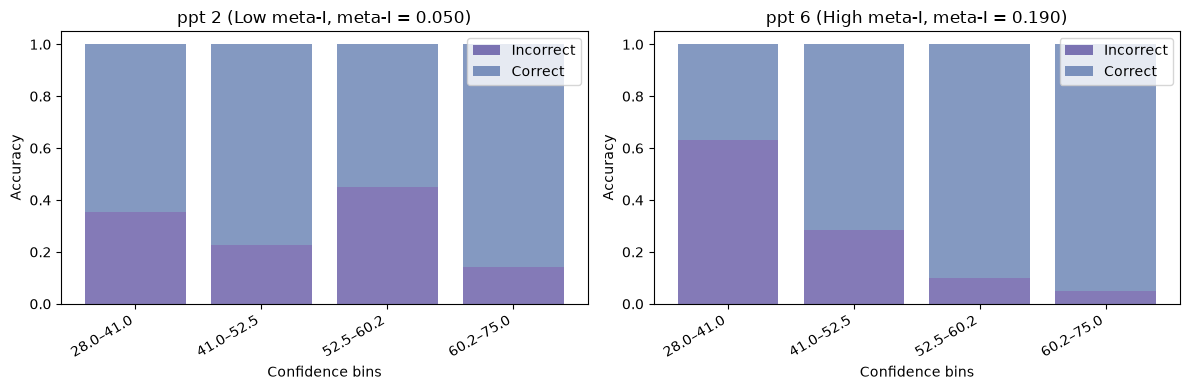

In [129]:
ppt_low = results_metaI[results_metaI["meta_I"].between(0.04, 0.06)].iloc[0]
ppt_high = results_metaI[results_metaI["meta_I"].between(0.15, 0.20)].iloc[0]

ppt_high_id = ppt_high["ppt"]
ppt_low_id = ppt_low["ppt"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for col, (row, label) in enumerate([(ppt_low, "Low meta-I"), (ppt_high, "High meta-I")]):
    n_correct_bin   = np.array(row["n_correct_bin"])
    n_incorrect_bin = np.array(row["n_incorrect_bin"])
    thresholds      = row["thresholds"]
    ppt_id          = row["ppt"]

    n_bins = len(n_correct_bin)
    x = np.arange(n_bins)   

    total        = n_correct_bin + n_incorrect_bin
    prop_correct = np.where(total > 0, n_correct_bin / total, np.nan)
    prop_incorrect = 1 - prop_correct

    axes[col].bar(x, prop_incorrect, label="Incorrect", color="#328",   alpha=0.6)
    axes[col].bar(x, prop_correct,   label="Correct",   color="#359", alpha=0.6,
            bottom=prop_incorrect)
    axes[col].set_xlabel("Confidence bins")
    axes[col].set_ylabel("Accuracy")
    axes[col].set_xticks(x)
    axes[col].set_xticklabels(bin_labels, rotation=30, ha="right")
    axes[col].set_title(f"ppt {ppt_id} ({label}, meta-I = {row['meta_I']:.3f})")
    axes[col].legend()


plt.tight_layout()
plt.show()


For the participant with higher meta-I score, the confidence is informative about the acrruacy: The participant is more confident, when they are more likely to be correct. In contrast: for the participant with a relativly low meta-I, confidence doesn't tell us much about having made the correct vs. incorrect decision.

The space observer task uses a staircase procedure, which holds participants ar ~75% accuracy, such that d' is relatively stable at 1.2 across participants. That way the metacognitive efficiency measures meta-Ir1 and meta-Ir2 are only rescaled meta-I and show the same trend for the correlation with H2(r|c) as well as the trial counts per confidence bin.

(0.0, 1.6778104017425222)

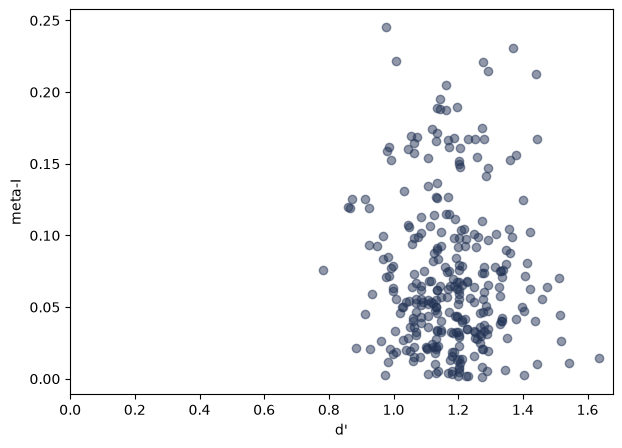

In [ ]:
fig, axes = plt.subplots(figsize = (7, 5))
axes.scatter(results_metaI["d_prime"], results_metaI["meta_I"], color = "#235", alpha = 0.5)
axes.set_xlabel("d'")
axes.set_ylabel("meta-I")
axes.set_xlim(0, )

## Summary and next steps

You estimated meta-$I$ and metacognitive efficiency measures for each participant of a perceptual decision-making task with [`EstimatorMetaI`](#cpm.applications.metainformation_theoretic.EstimatorMetaI).
To prepare your own data, [`count_trials`](#cpm.utils.metai.bin_counts) converts trial-level data into the response counts that the meta-$I$ model uses, and [`conf_binned`](#cpm.utils.metai.conf_binned) bins continuous confidence ratings.
To fit many participants faster, see the how-to guide on [parallel fitting](../how-to/parallelise-fitting.md).

## References

Dayan, P. (2023). Metacognitive Information Theory. *Open Mind*: Discoveries in Cognitive Science. https://doi.org/10.1162/opmi_a_00091

Marzuki, A., Kosina, L., Dome, L., Hewitt, S., & Hauser, T. (2025). Metacognitive antecedents to states of mental ill-health: Drops in confidence precede symptoms of OCD. *Research Square*. https://doi.org/10.21203/rs.3.rs-7544256/v1

## Comparing meta-d' and meta-I

In [8]:
display(results_metad[["ppt", "d", "meta_d", "m_ratio"]].head())
display(results_metaI[["ppt", "d_prime", "meta_I", "meta_Ir1", "meta_Ir2"]].head())

,ppt,d,meta_d,m_ratio
0,1,1.359242,1.314121,0.966805
1,2,1.029980,0.584894,0.567869
2,3,1.039519,0.405863,0.390434
3,4,1.272349,0.737918,0.579965
4,5,1.256566,1.382703,1.100382


,ppt,d_prime,meta_I,meta_Ir1,meta_Ir2
0,1,1.359242,0.087764,1.187114,0.110973
1,2,1.029980,0.050283,1.030482,0.058099
2,3,1.039519,0.020070,0.405268,0.023190
3,4,1.272349,0.020873,0.308644,0.025728
4,5,1.256566,0.091895,1.383739,0.112582


### Correlating meta-d'and meta-I

In [11]:
meta_d = results_metad["meta_d"]
meta_I = results_metaI["meta_I"]

r, p = scipy.stats.pearsonr(meta_d, meta_I)
print(f" r = {r:.2f}, p = {p:.3f}")

 r = 0.87, p = 0.000


#### Visualized

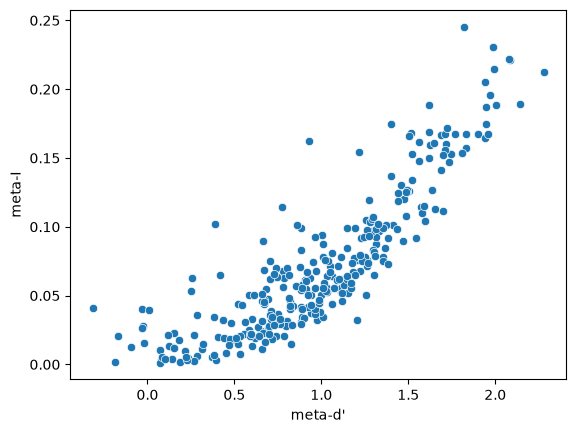

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(x = meta_d, y = meta_I)
plt.xlabel("meta-d'")
plt.ylabel("meta-I")
plt.show()